# CNN vs Random Forest

Side-by-side comparison of the two genre classifiers.

| | Random Forest | CNN |
|---|---|---|
| Input | 57 handcrafted audio features per 3-second clip (`features_3_sec.csv`) | Mel spectrogram image per 3-second clip |
| Model | `models/random_forest.json` | `models/cnn.json` |

**How the test set is used.** The model choice is made first, in *Model selection*, using only validation data and an
external set of jazz recordings. The holdout test set (200 songs, never used for training or for any choice) is only
used afterwards, to *report* how both final models perform. Nothing in this notebook is tuned on test results.

Chart titles are computed from the results, so they stay correct if the models are retrained.

In [1]:
import sys
import importlib.util
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_recall_fscore_support

NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (p / "pyproject.toml").is_file())
RF_MODULE_PATH = PROJECT_ROOT / "random_forest" / "random_forest_genres.py"
RF_MODEL_PATH = PROJECT_ROOT / "models" / "random_forest.json"
CNN_MODULE_PATH = PROJECT_ROOT / "cnn" / "cnn_genres_classifier.py"
CNN_MODEL_PATH = PROJECT_ROOT / "models" / "cnn.json"
EXTERNAL_RESULTS_PATH = PROJECT_ROOT / "test" / "results_evaluate_external.csv"
CHUNK_SIZE = 128


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


rf_module = load_module("random_forest_genres", RF_MODULE_PATH)
cnn_module = load_module("cnn_genres_classifier", CNN_MODULE_PATH)
with open(RF_MODEL_PATH, encoding="utf-8") as f:
    rf_results = json.load(f)
with open(CNN_MODEL_PATH, encoding="utf-8") as f:
    cnn_results = json.load(f)

assert rf_results["split"]["test_songs"] == cnn_results["split"]["test_songs"], "Models were tested on different songs"
labels = np.asarray(rf_results["model"]["classes"], dtype=object)
assert labels.tolist() == cnn_results["model"]["classes"], "Models use a different class order"
MODELS = ["Random Forest", "CNN"]

# Chart style. One fixed color per model in every chart: Random Forest = blue, CNN = orange.
COLORS = {"Random Forest": "#2a78d6", "CNN": "#eb6834"}
NEUTRAL = {"both right": "#c3c2b7", "both wrong": "#52514e"}
INK, INK_SECONDARY, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "legend.frameon": False,
        "lines.linewidth": 2,
        "font.size": 10,
    }
)


def points(value):
    return f"{value * 100:+.1f} pts"


def leader(scores):
    """Name of the model with the higher score and its margin over the other one."""
    best = max(scores, key=scores.get)
    return best, scores[best] - min(scores.values())

## Model selection (no test data)

Which model should the playlist filter use? This is decided **before** looking at the test set, from two sources:

1. **Validation accuracy** from training. The random forest's value is the mean of its 5-fold cross-validation (grouped
   by song) on the 80% training data; the CNN's is its accuracy on a held-out validation split (15% of the training
   songs) at the epoch kept by early stopping. The protocols are not identical (5 folds vs one split), so small
   differences should not be over-read.
2. **External jazz recordings** (`test/results_evaluate_external.csv`): real jazz tracks downloaded from YouTube that
   are not part of GTZAN. They are all jazz, so they measure jazz recall only: the share of jazz the filter would keep.
   If the models are retrained, rerun `test/evaluate_external.py` so this file matches them.

,Validation accuracy,Validation protocol,External jazz kept,External songs
Random Forest,0.692752,"5-fold CV, ± 0.024 between folds",0.520548,73
CNN,0.725217,"single split (115 songs), epoch 32",0.849315,73


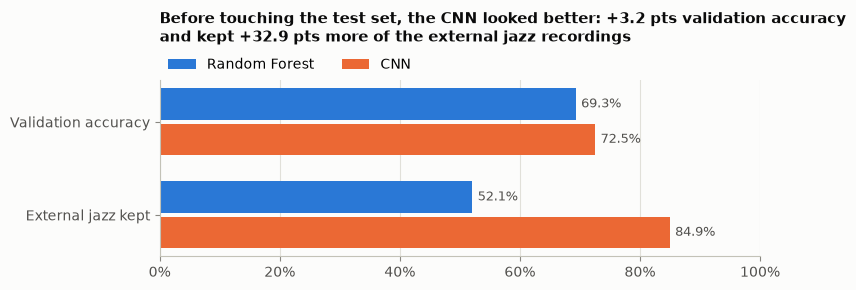

In [2]:
selection = pd.DataFrame(
    {
        "Validation accuracy": {
            "Random Forest": rf_results["cross_validation"]["validation_accuracy"],
            "CNN": cnn_results["training"]["best_validation_accuracy"],
        },
        "Validation protocol": {
            "Random Forest": f"5-fold CV, ± {rf_results['cross_validation']['validation_std']:.3f} between folds",
            "CNN": f"single split ({len(cnn_results['split']['validation_songs'])} songs), epoch {cnn_results['training']['best_epoch']}",
        },
    }
)

external = None
if EXTERNAL_RESULTS_PATH.is_file():
    external = pd.read_csv(EXTERNAL_RESULTS_PATH)
    external["prediction"] = external[labels.tolist()].idxmax(axis=1)
    names = {"random_forest": "Random Forest", "cnn": "CNN"}
    recall = external.groupby("model")["prediction"].apply(lambda p: (p == "jazz").mean()).rename(index=names)
    songs = external.groupby("model").size().rename(index=names)
    selection["External jazz kept"] = recall
    selection["External songs"] = songs
display(selection)

measures = ["Validation accuracy"] + (["External jazz kept"] if external is not None else [])
validation_winner, validation_margin = leader(selection["Validation accuracy"].to_dict())
title = f"Before touching the test set, the {validation_winner} looked better: {points(validation_margin)} validation accuracy"
if external is not None:
    external_winner, external_margin = leader(selection["External jazz kept"].to_dict())
    if external_winner == validation_winner:
        title += f"\nand kept {points(external_margin)} more of the external jazz recordings"
    else:
        title += f"\nbut the {external_winner} kept {points(external_margin)} more of the external jazz recordings"

fig, ax = plt.subplots(figsize=(8, 1.2 + 0.9 * len(measures)))
y = np.arange(len(measures))
height = 0.38
for offset, name in zip([-height / 2, height / 2], MODELS):
    values = selection.loc[name, measures].astype(float).values
    bars = ax.barh(y + offset, values, height=height - 0.04, color=COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=4, color=INK_SECONDARY, fontsize=9)
ax.set_yticks(y, measures)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_title(title, pad=28)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
plt.tight_layout()
plt.show()

## Test set results

Everything from here on uses the holdout test set: 200 songs (2,000 three-second clips) that neither model saw during
training, validation or model selection. Both models were split with `StratifiedGroupKFold(random_state=42)` by song,
so they are tested on exactly the same clips.

Both models are loaded from their JSON files and run with NumPy only (no PyTorch or GPU needed).

In [3]:
# Random forest: features CSV
rf_model = rf_module.RandomForestFromJSON(rf_results["model"])
features = pd.read_csv(PROJECT_ROOT / rf_results["metadata"]["data_path"])
id_parts = features["filename"].astype(str).str.extract(rf_results["config"]["song_id_pattern"])
features["song_id"] = id_parts[0].str.lower() + id_parts[1]
features = features[features["song_id"].isin(rf_results["split"]["test_songs"])]
features = features.sort_values("filename").reset_index(drop=True)
rf_proba = rf_model.predict_proba(features)

# CNN: spectrogram PNGs
paths = sorted((PROJECT_ROOT / cnn_results["metadata"]["data_path"]).rglob("*.png"))
images = pd.DataFrame({"path": paths, "filename": [p.stem for p in paths], "label": [p.parent.name for p in paths]})
id_parts = images["filename"].str.extract(cnn_results["config"]["song_id_pattern"])
images["song_id"] = id_parts[0].str.lower() + id_parts[1]
images = images[images["song_id"].isin(cnn_results["split"]["test_songs"])]
images = images.sort_values("filename").reset_index(drop=True)
cnn_proba = np.concatenate(
    [
        cnn_module.predict_proba(
            np.stack([cnn_module.load_spectrogram_png(p) for p in images["path"].iloc[start:start + CHUNK_SIZE]]),
            CNN_MODEL_PATH,
        )[1]
        for start in range(0, len(images), CHUNK_SIZE)
    ]
)

# One row per holdout clip, aligned by filename
assert (features["filename"].astype(str).values == images["filename"].values).all(), "Clips do not line up"
df = images[["filename", "song_id", "label", "path"]].copy()
df["rf_pred"] = labels[rf_proba.argmax(axis=1)]
df["cnn_pred"] = labels[cnn_proba.argmax(axis=1)]
df["rf_correct"] = df["rf_pred"] == df["label"]
df["cnn_correct"] = df["cnn_pred"] == df["label"]
probas = {"Random Forest": rf_proba, "CNN": cnn_proba}
preds = {"Random Forest": df["rf_pred"], "CNN": df["cnn_pred"]}

# Song level: average the clip probabilities of each song
songs = df.groupby("song_id")["label"].first()
song_probas = {name: pd.DataFrame(p, columns=labels).groupby(df["song_id"].values).mean().loc[songs.index] for name, p in probas.items()}
song_preds = {name: p.idxmax(axis=1) for name, p in song_probas.items()}

print(f"Holdout clips: {len(df)} | Songs: {len(songs)}")
print(f"Random Forest accuracy: {df['rf_correct'].mean():.4f} | Stored: {rf_results['holdout']['accuracy']:.4f}")
print(f"CNN accuracy:           {df['cnn_correct'].mean():.4f} | Stored: {cnn_results['holdout']['accuracy']:.4f}")

Holdout clips: 2000 | Songs: 200
Random Forest accuracy: 0.7135 | Stored: 0.7135
CNN accuracy:           0.7430 | Stored: 0.7430


### Overall

Clip accuracy scores every 3-second clip on its own. Song accuracy averages the clip probabilities of each song first,
which is how the jazz filter decides on a full track.

,Random Forest,CNN
Clip accuracy,0.7135,0.743
Song accuracy,0.78,0.81
Macro F1 (clips),0.711569,0.74166
Log loss (clips),0.936811,0.845299
Model size,"500 trees, 1,133,914 nodes","172,362 parameters"
Model file (MB),47.0,3.5


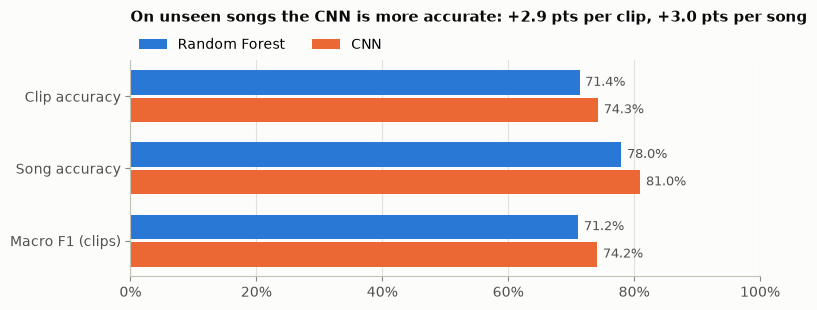

In [4]:
def model_size(name):
    if name == "Random Forest":
        trees = rf_results["model"]["trees"]
        return f"{len(trees)} trees, {sum(len(t['children_left']) for t in trees):,} nodes"
    return f"{cnn_results['architecture']['total_parameters']:,} parameters"


summary = pd.DataFrame(
    {
        name: {
            "Clip accuracy": accuracy_score(df["label"], preds[name]),
            "Song accuracy": accuracy_score(songs, song_preds[name]),
            "Macro F1 (clips)": f1_score(df["label"], preds[name], average="macro"),
            "Log loss (clips)": log_loss(df["label"], probas[name], labels=labels),
            "Model size": model_size(name),
            "Model file (MB)": round((RF_MODEL_PATH if name == "Random Forest" else CNN_MODEL_PATH).stat().st_size / 1024 ** 2, 1),
        }
        for name in MODELS
    }
)
display(summary)

metrics_to_plot = ["Clip accuracy", "Song accuracy", "Macro F1 (clips)"]
clip_winner, clip_margin = leader(summary.loc["Clip accuracy"].astype(float).to_dict())
song_margin = summary.loc["Song accuracy", clip_winner] - summary.loc["Song accuracy"].drop(clip_winner).iloc[0]
title = f"On unseen songs the {clip_winner} is more accurate: {points(clip_margin)} per clip, {points(song_margin)} per song"

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(metrics_to_plot))
for offset, name in zip([-height / 2, height / 2], MODELS):
    values = summary.loc[metrics_to_plot, name].astype(float).values
    bars = ax.barh(y + offset, values, height=height - 0.04, color=COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=4, color=INK_SECONDARY, fontsize=9)
ax.set_yticks(y, metrics_to_plot)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_title(title, pad=28)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
plt.tight_layout()
plt.show()

### Per genre

Precision: of the clips a model labels as a genre, how many really are that genre. Recall: of the clips of a genre,
how many the model finds.

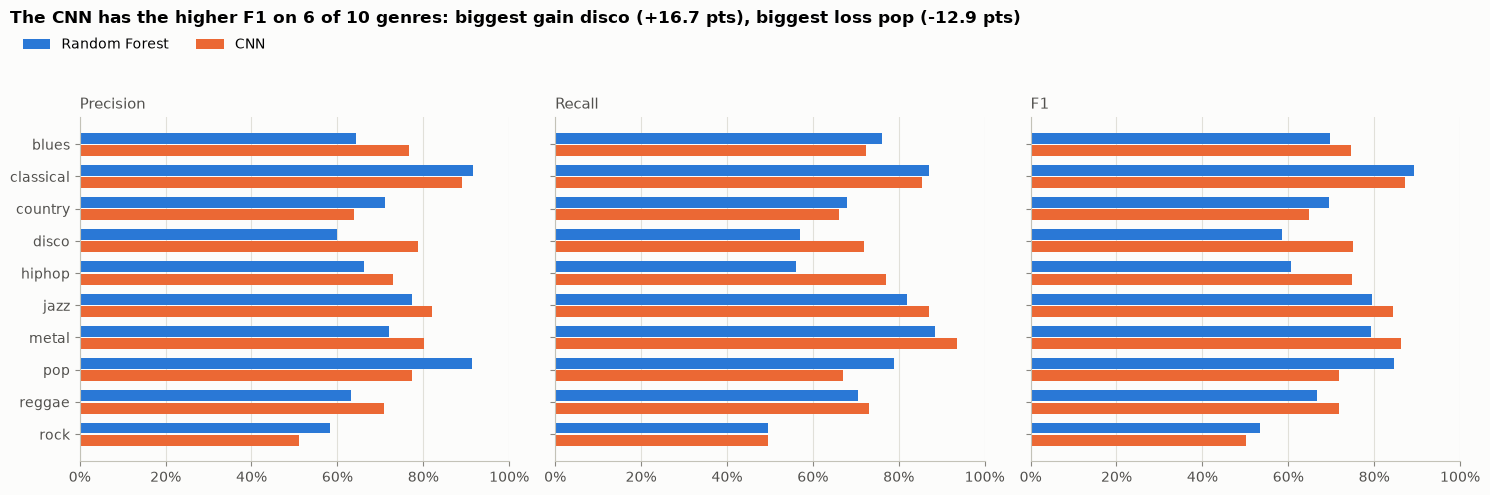

Random Forest                     CNN               CNN - RF
              precision recall     f1 precision recall     f1       f1
disco             0.600  0.570  0.585     0.787  0.720  0.752    0.167
hiphop            0.663  0.560  0.607     0.730  0.770  0.749    0.142
metal             0.720  0.885  0.794     0.803  0.935  0.864    0.070
reggae            0.632  0.705  0.667     0.709  0.730  0.719    0.053
jazz              0.774  0.820  0.796     0.821  0.870  0.845    0.049
blues             0.644  0.760  0.697     0.767  0.725  0.746    0.048
classical         0.916  0.870  0.892     0.891  0.855  0.872   -0.020
rock              0.582  0.495  0.535     0.510  0.495  0.503   -0.033
country           0.712  0.680  0.696     0.638  0.660  0.649   -0.047
pop               0.913  0.790  0.847     0.775  0.670  0.718   -0.129

In [5]:
per_genre = {}
for name in MODELS:
    precision, recall, f1, _ = precision_recall_fscore_support(df["label"], preds[name], labels=labels, zero_division=0)
    per_genre[name] = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1}, index=labels)

f1_gap = per_genre["CNN"]["f1"] - per_genre["Random Forest"]["f1"]
cnn_wins = int((f1_gap > 0).sum())
title = (
    f"The CNN has the higher F1 on {cnn_wins} of {len(labels)} genres: biggest gain {f1_gap.idxmax()} ({points(f1_gap.max())}), "
    f"biggest loss {f1_gap.idxmin()} ({points(f1_gap.min())})"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
y = np.arange(len(labels))
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    for offset, name in zip([-height / 2, height / 2], MODELS):
        ax.barh(y + offset, per_genre[name][metric], height=height - 0.04, color=COLORS[name], label=name)
    ax.set_title(metric.capitalize() if metric != "f1" else "F1", fontweight="normal", color=INK_SECONDARY)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, labels)
axes[0].invert_yaxis()
fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.legend(*axes[0].get_legend_handles_labels(), ncols=2, loc="upper left", bbox_to_anchor=(0.01, 0.95))
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

comparison = pd.concat({name: table for name, table in per_genre.items()}, axis=1)
comparison[("CNN - RF", "f1")] = f1_gap
display(comparison.sort_values(("CNN - RF", "f1"), ascending=False).round(3))

### Confusion matrices

Rows are the true genre and each row sums to 100%. The third panel subtracts the two: orange cells are where the CNN
puts more clips than the random forest, blue cells where the random forest does. On the diagonal, orange means the CNN
gets that genre right more often; off the diagonal, orange means the CNN makes that mistake more often.

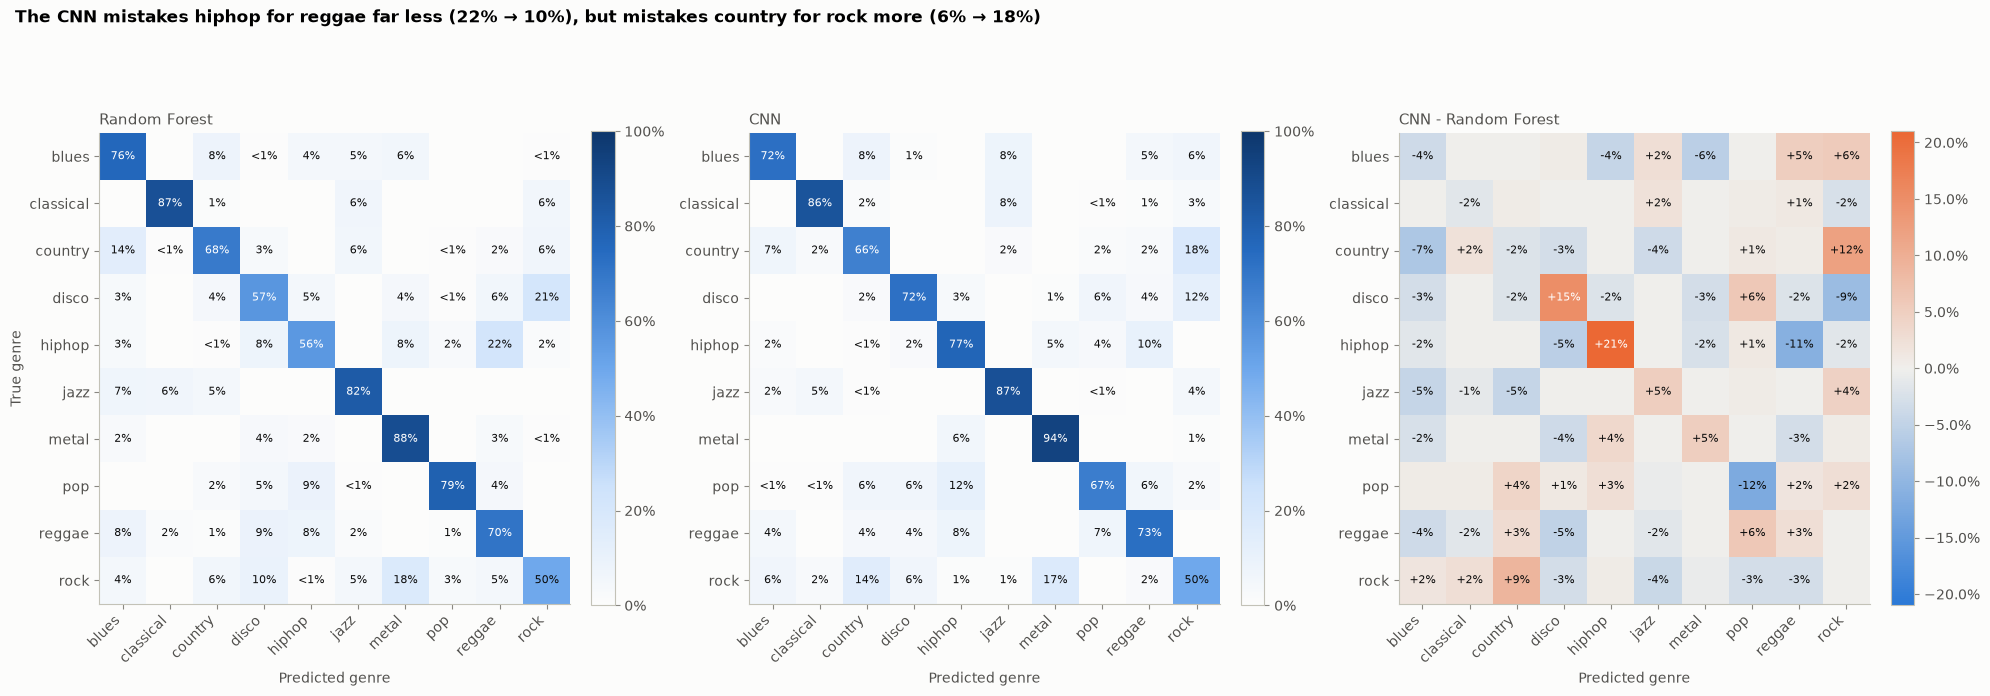

In [6]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.metrics import confusion_matrix

sequential = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
diverging = LinearSegmentedColormap.from_list("div", [COLORS["Random Forest"], "#f0efec", COLORS["CNN"]])

matrices = {name: confusion_matrix(df["label"], preds[name], labels=labels, normalize="true") for name in MODELS}
matrices["CNN - Random Forest"] = matrices["CNN"] - matrices["Random Forest"]

off_diagonal = pd.DataFrame(matrices["CNN - Random Forest"], index=labels, columns=labels)
off_diagonal = off_diagonal.where(~np.eye(len(labels), dtype=bool)).stack()
(fixed_true, fixed_pred), (worse_true, worse_pred) = off_diagonal.idxmin(), off_diagonal.idxmax()
cell = lambda name, t, p: matrices[name][list(labels).index(t), list(labels).index(p)]
title = (
    f"The CNN mistakes {fixed_true} for {fixed_pred} far less ({cell('Random Forest', fixed_true, fixed_pred):.0%} → "
    f"{cell('CNN', fixed_true, fixed_pred):.0%}), but mistakes {worse_true} for {worse_pred} more "
    f"({cell('Random Forest', worse_true, worse_pred):.0%} → {cell('CNN', worse_true, worse_pred):.0%})"
)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (name, matrix) in zip(axes, matrices.items()):
    if name == "CNN - Random Forest":
        limit = np.abs(matrix).max()
        image = ax.imshow(matrix, cmap=diverging, norm=TwoSlopeNorm(0, -limit, limit))
        text = lambda v: f"{v:+.0%}" if abs(v) >= 0.0075 else ""  # hide single-clip (0.5%) differences
    else:
        image = ax.imshow(matrix, cmap=sequential, vmin=0, vmax=1)
        text = lambda v: "" if v == 0 else ("<1%" if v < 0.0075 else f"{v:.0%}")
    for i in range(len(labels)):
        for j in range(len(labels)):
            value = matrix[i, j]
            dark_cell = (name != "CNN - Random Forest" and value > 0.55) or (name == "CNN - Random Forest" and abs(value) > 0.6 * limit)
            ax.text(j, i, text(value), ha="center", va="center", fontsize=8, color="#ffffff" if dark_cell else INK)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.grid(False)
    ax.set_title(name, fontweight="normal", color=INK_SECONDARY)
    ax.set_xlabel("Predicted genre")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, format=PercentFormatter(1.0))
axes[0].set_ylabel("True genre")
fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### Where the models agree and disagree

Every holdout clip falls into one of four groups. If the models made the same mistakes, combining them would not help;
the more "only one right" clips there are, the more they complement each other.

McNemar's test checks whether the accuracy difference is larger than chance, using only the clips where exactly one
model is right.

,clips,share
both right,1180,0.590
only CNN right,306,0.153
only Random Forest right,247,0.124
both wrong,267,0.134


McNemar exact test: CNN-only 306 vs RF-only 247 clips, p = 0.014


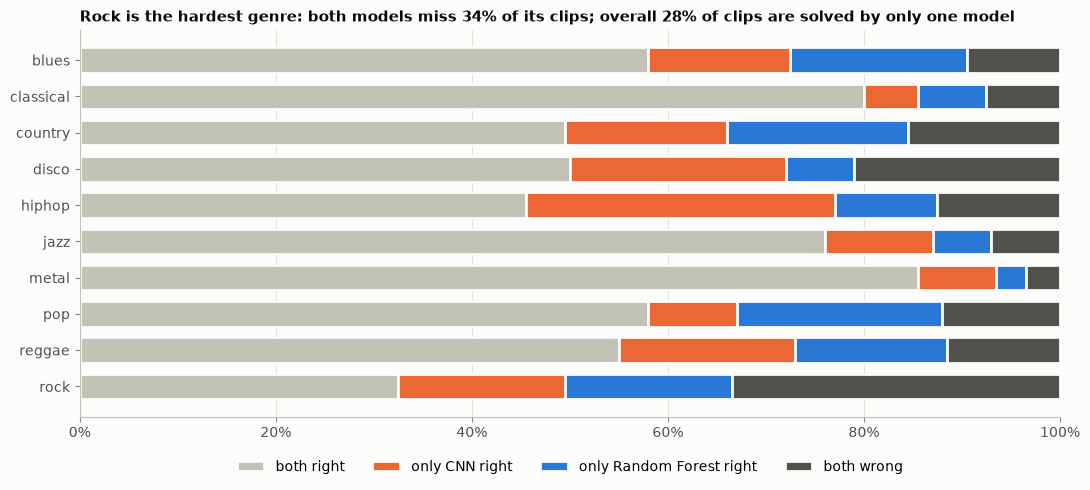

In [7]:
from scipy.stats import binomtest

outcome = np.select(
    [df["rf_correct"] & df["cnn_correct"], df["cnn_correct"], df["rf_correct"]],
    ["both right", "only CNN right", "only Random Forest right"],
    "both wrong",
)
order = ["both right", "only CNN right", "only Random Forest right", "both wrong"]
outcome_colors = [NEUTRAL["both right"], COLORS["CNN"], COLORS["Random Forest"], NEUTRAL["both wrong"]]
counts = pd.Series(outcome).value_counts().reindex(order, fill_value=0)
display(pd.DataFrame({"clips": counts, "share": (counts / len(df)).round(3)}))

only_cnn, only_rf = counts["only CNN right"], counts["only Random Forest right"]
p_value = binomtest(int(only_cnn), int(only_cnn + only_rf), 0.5).pvalue
print(f"McNemar exact test: CNN-only {only_cnn} vs RF-only {only_rf} clips, p = {p_value:.2g}")

shares = pd.crosstab(df["label"], outcome, normalize="index").reindex(columns=order, fill_value=0).loc[labels]
hardest = shares["both wrong"].idxmax()
title = (
    f"{hardest.capitalize()} is the hardest genre: both models miss {shares.loc[hardest, 'both wrong']:.0%} of its clips; "
    f"overall {(only_cnn + only_rf) / len(df):.0%} of clips are solved by only one model"
)

fig, ax = plt.subplots(figsize=(11, 5))
left = np.zeros(len(shares))
for column, color in zip(order, outcome_colors):
    ax.barh(shares.index, shares[column], left=left, color=color, edgecolor="#fcfcfb", linewidth=2, label=column, height=0.7)
    left += shares[column].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_title(title)
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.show()

### Confidence

The confidence of a prediction is the probability the model gives to its top genre. A well-calibrated model is right
about 70% of the time when it says 70%; points above the dashed line mean the model is underconfident (right more often
than it claims), points below it mean overconfident.

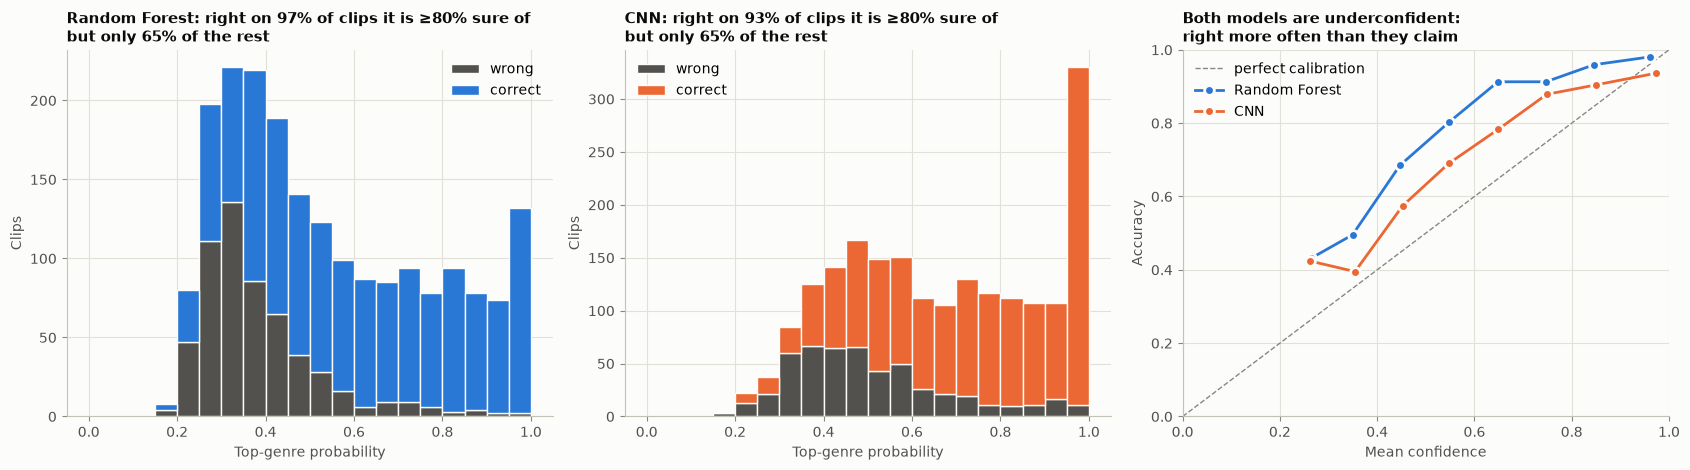

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
bins = np.linspace(0, 1, 21)
for ax, name in zip(axes[:2], MODELS):
    confidence = probas[name].max(axis=1)
    correct = preds[name].values == df["label"].values
    ax.hist([confidence[~correct], confidence[correct]], bins=bins, stacked=True, color=[NEUTRAL["both wrong"], COLORS[name]],
            label=["wrong", "correct"], edgecolor="#fcfcfb", linewidth=1)
    sure = confidence >= 0.8
    ax.set_title(f"{name}: right on {correct[sure].mean():.0%} of clips it is ≥80% sure of\n"
                 f"but only {correct[~sure].mean():.0%} of the rest")
    ax.set_xlabel("Top-genre probability")
    ax.set_ylabel("Clips")
    ax.legend()

ax = axes[2]
ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED, linewidth=1, label="perfect calibration")
gaps = {}
for name in MODELS:
    confidence = probas[name].max(axis=1)
    correct = preds[name].values == df["label"].values
    gaps[name] = correct.mean() - confidence.mean()
    bin_index = np.clip(np.digitize(confidence, np.linspace(0, 1, 11)) - 1, 0, 9)
    calibration = pd.DataFrame({"bin": bin_index, "confidence": confidence, "correct": correct}).groupby("bin").agg(
        confidence=("confidence", "mean"), accuracy=("correct", "mean"), clips=("correct", "size")
    )
    calibration = calibration[calibration["clips"] >= 10]
    ax.plot(calibration["confidence"], calibration["accuracy"], color=COLORS[name], marker="o", markersize=7,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=name)
kind = lambda gap: "underconfident" if gap > 0 else "overconfident"
if kind(gaps["CNN"]) == kind(gaps["Random Forest"]):
    calibration_title = f"Both models are {kind(gaps['CNN'])}:\nright more often than they claim" if gaps["CNN"] > 0 else \
        f"Both models are {kind(gaps['CNN'])}:\nright less often than they claim"
else:
    calibration_title = f"The CNN is {kind(gaps['CNN'])},\nthe random forest {kind(gaps['Random Forest'])}"
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(calibration_title)
ax.set_xlabel("Mean confidence")
ax.set_ylabel("Accuracy")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### The jazz filter

The project's real task is binary: play a song if it is jazz, skip it otherwise. Here each model's jazz probability is
used on its own. The ROC curve shows every possible threshold; the table uses the rule the playlist filter applies
(keep only if jazz is the most likely genre), at song level.

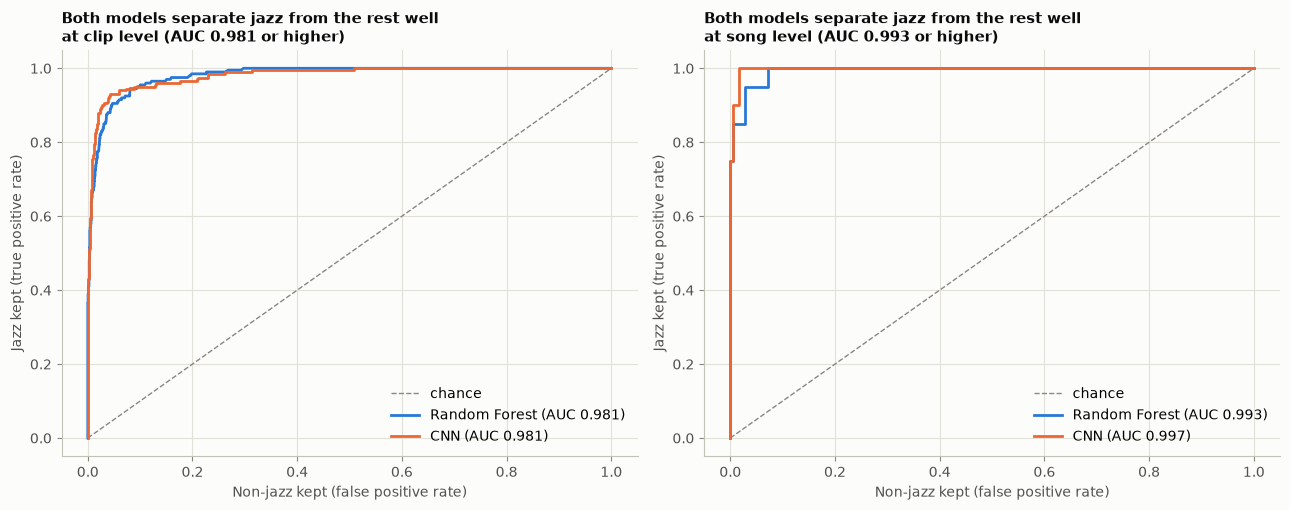

,Random Forest,CNN
Jazz songs kept,17 / 20,18 / 20
Jazz songs wrongly removed,3,2
Non-jazz songs wrongly kept,3,3
Kept songs that are jazz (precision),0.85,0.857


In [9]:
from sklearn.metrics import roc_auc_score, roc_curve

jazz = list(labels).index("jazz")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, level in zip(axes, ["clip", "song"]):
    ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED, linewidth=1, label="chance")
    aucs = {}
    for name in MODELS:
        if level == "clip":
            truth, score = df["label"].values == "jazz", probas[name][:, jazz]
        else:
            truth, score = songs.values == "jazz", song_probas[name]["jazz"].values
        fpr, tpr, _ = roc_curve(truth, score)
        aucs[name] = roc_auc_score(truth, score)
        ax.plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {aucs[name]:.3f})")
    quality = "well" if min(aucs.values()) >= 0.9 else "only moderately"
    ax.set_title(f"Both models separate jazz from the rest {quality}\nat {level} level (AUC {min(aucs.values()):.3f} or higher)")
    ax.set_xlabel("Non-jazz kept (false positive rate)")
    ax.set_ylabel("Jazz kept (true positive rate)")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

rows = {}
for name in MODELS:
    kept = song_preds[name].values == "jazz"
    is_jazz = songs.values == "jazz"
    rows[name] = {
        "Jazz songs kept": f"{(kept & is_jazz).sum()} / {is_jazz.sum()}",
        "Jazz songs wrongly removed": int((~kept & is_jazz).sum()),
        "Non-jazz songs wrongly kept": int((kept & ~is_jazz).sum()),
        "Kept songs that are jazz (precision)": round((kept & is_jazz).sum() / max(kept.sum(), 1), 3),
    }
display(pd.DataFrame(rows))

### Averaging the two models

Because the models make partly different mistakes, averaging their probabilities may beat both. The weights are fixed
in advance at a plain 50/50 average and **not tuned**: tuning them here would use the test set to make a decision.
Tuning them properly would need validation predictions from both models on the same songs, which the random forest
does not have (its cross-validation used all training songs).

,Random Forest,CNN,50/50 average
Clip accuracy,0.7135,0.743,0.7965
Song accuracy,0.7800,0.810,0.8550


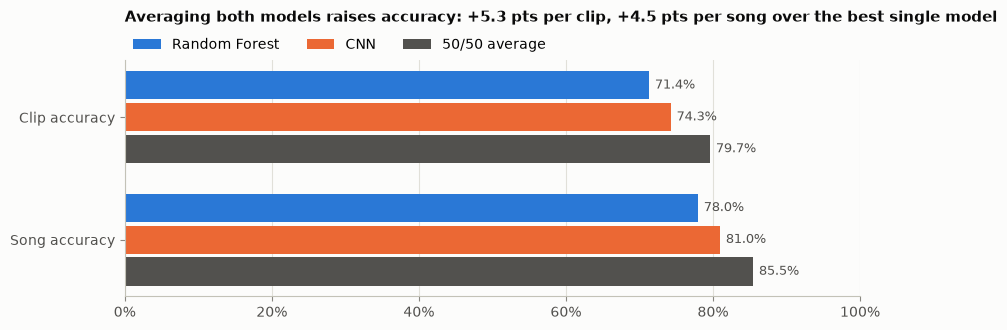

In [10]:
average_proba = (rf_proba + cnn_proba) / 2
average_songs = pd.DataFrame(average_proba, columns=labels).groupby(df["song_id"].values).mean().loc[songs.index]
combined = pd.DataFrame(
    {
        "Random Forest": [summary.loc["Clip accuracy", "Random Forest"], summary.loc["Song accuracy", "Random Forest"]],
        "CNN": [summary.loc["Clip accuracy", "CNN"], summary.loc["Song accuracy", "CNN"]],
        "50/50 average": [accuracy_score(df["label"], labels[average_proba.argmax(axis=1)]),
                          accuracy_score(songs, average_songs.idxmax(axis=1))],
    },
    index=["Clip accuracy", "Song accuracy"],
).astype(float)
display(combined.round(4))

best_single = combined[MODELS].max(axis=1)
gain = combined["50/50 average"] - best_single
verb = "raises" if (gain > 0).all() else "does not clearly improve"
title = f"Averaging both models {verb} accuracy: {points(gain['Clip accuracy'])} per clip, {points(gain['Song accuracy'])} per song over the best single model"

fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(2)
bar_height = 0.26
colors = [COLORS["Random Forest"], COLORS["CNN"], NEUTRAL["both wrong"]]
for k, (column, color) in enumerate(zip(combined.columns, colors)):
    bars = ax.barh(y + (k - 1) * bar_height, combined[column], height=bar_height - 0.03, color=color, label=column)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in combined[column]], padding=4, color=INK_SECONDARY, fontsize=9)
ax.set_yticks(y, combined.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_title(title, pad=28)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
plt.tight_layout()
plt.show()

### Clips where only one model is right

Spectrograms from the holdout set where the models disagree, picked at random.

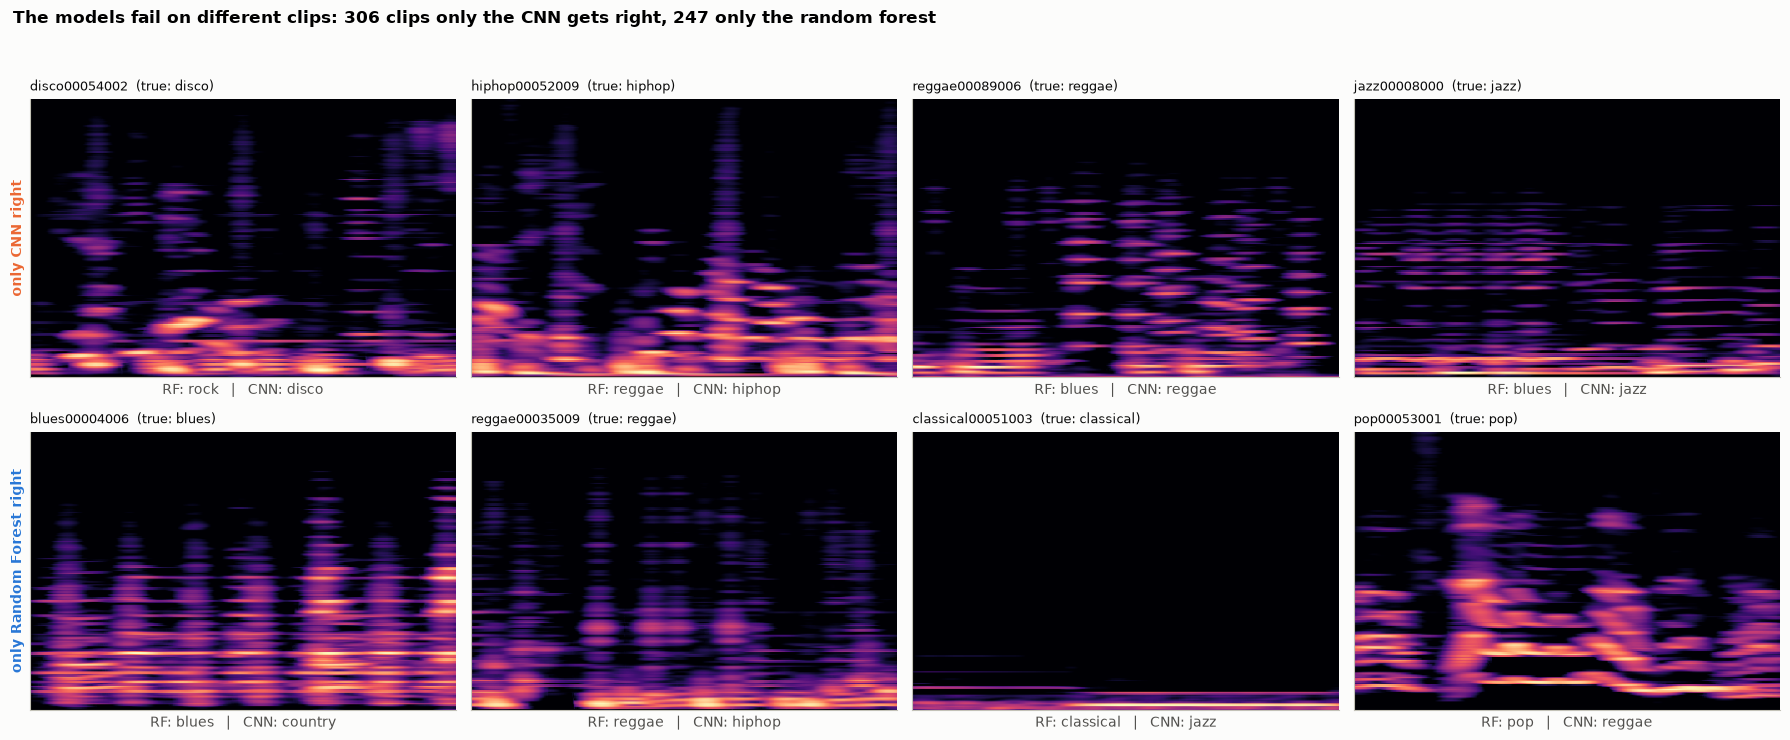

In [11]:
rng = np.random.default_rng(0)
groups = [("only CNN right", df[df["cnn_correct"] & ~df["rf_correct"]]), ("only Random Forest right", df[df["rf_correct"] & ~df["cnn_correct"]])]
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for row, (title, subset) in zip(axes, groups):
    picks = subset.iloc[rng.choice(len(subset), size=min(4, len(subset)), replace=False)] if len(subset) else subset
    for ax, (_, clip) in zip(row, picks.iterrows()):
        ax.imshow(cnn_module.load_spectrogram_png(clip["path"]), aspect="auto")
        ax.set_title(f"{clip['filename']}  (true: {clip['label']})", fontsize=9, loc="left", fontweight="normal")
        ax.set_xlabel(f"RF: {clip['rf_pred']}   |   CNN: {clip['cnn_pred']}", color=INK_SECONDARY)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    row[0].set_ylabel(title, color=COLORS["CNN" if title.startswith("only CNN") else "Random Forest"], fontweight="bold")
fig.suptitle(
    f"The models fail on different clips: {len(groups[0][1])} clips only the CNN gets right, {len(groups[1][1])} only the random forest",
    x=0.01, ha="left", fontweight="bold", fontsize=12,
)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()